# Méthode proposée : régression bayésienne contrainte par la physique

**Idée en une phrase.** On garde la relation physique $T = a + b\ln(\mathrm{CO_2})$, mais au lieu d'estimer *une* valeur de $(a, b, \sigma)$, on tire 10 000 jeux de paramètres plausibles dans leur loi *a posteriori*, avec la seule contrainte physique « plus de CO$_2$ ne refroidit pas » ($b \ge 0$). Chaque tirage de température combine ainsi la **variabilité naturelle** d'une année à l'autre et **notre incertitude sur les paramètres**, qui grandit quand on extrapole vers 946 ppm.

**Résultat au benchmark du groupe : 1,58 °C** (référence : 1,70 °C), départage (minimum) : 1,06 °C, tests de cohérence OK.

Règles du groupe respectées : apprentissage sur 1940–2000 uniquement, seule entrée pour 2001–2025 et 2100 = le CO$_2$, `verite_2001_2025.csv` jamais lu par le modèle (seulement par `kit.benchmark`), graine fixée.

**Lancer :** ce notebook doit être dans le même dossier que `kit.py` et `data/`. Puis *Exécuter tout*.

In [1]:
# Sur Google Colab uniquement : envoyer le zip du kit dans « Fichiers », puis décommenter les 2 lignes
# !unzip -o -q a_envoyer*.zip
# %cd a_envoyer

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import norm
import kit

rng = np.random.default_rng(0)                         # graine fixée : score reproductible
jour, an, test, futur = kit.charger()
N = kit.N_TIRAGES
co2_test = test.co2.to_numpy()                         # 2001-2025 (ppm)
co2_fut = futur[list(kit.SCENARIOS)].to_numpy()        # 2026-2100 x 3 scénarios (ppm)
annees_fut = futur.valid_time.dt.year.to_numpy()

## 1. Le modèle

Pour une variable $T_t$ (maximum ou minimum annuel, en °C) et le CO$_2$ $C_t$ (ppm), on note $x_t = \ln C_t - \bar x$, où $\bar x$ est la moyenne de $\ln C_t$ sur 1940–2000. Le logarithme vient de la physique : le forçage radiatif du CO$_2$ vaut $\Delta F \approx 5{,}35\,\ln(C/C_0)$ W/m², la réponse en température est donc d'abord linéaire en $\ln C$.

$$T_t = a + b\,x_t + \sigma\,\varepsilon_t, \qquad \varepsilon_t \overset{iid}{\sim} \mathcal N(0,1).$$

**Loi a priori.** Non informative, sauf la contrainte physique :
$$p(a, b, \sigma^2) \propto \sigma^{-2}\,\mathbf 1\{b \ge 0\}.$$

**Loi a posteriori.** Avec $X = [\mathbf 1, x]$ ($n = 61$ lignes), $\hat\beta = (X^\top X)^{-1}X^\top T$ et $s^2 = \lVert T - X\hat\beta\rVert^2/(n-2)$ :
$$\sigma^2 \mid T \sim \frac{(n-2)\,s^2}{\chi^2_{n-2}}, \qquad (a, b) \mid \sigma^2, T \sim \mathcal N\!\big(\hat\beta,\ \sigma^2 (X^\top X)^{-1}\big)\ \text{restreinte à } b \ge 0.$$
On l'échantillonne **exactement par rejet** : on tire dans la loi sans contrainte et on ne garde que les tirages avec $b \ge 0$.

**Prévision probabiliste.** Pour un CO$_2$ futur $C$ et chaque $k = 1, \dots, N$ ($N = 10\,000$) :
$$T^{(k)}(C) = a^{(k)} + b^{(k)}\,(\ln C - \bar x) + \sigma^{(k)} z^{(k)}, \qquad z^{(k)} \sim \mathcal N(0,1).$$
On utilise le même $z^{(k)}$ pour toutes les années et tous les scénarios (aléas communs) : la loi de chaque année est inchangée, mais les écarts entre scénarios ne dépendent plus du hasard des tirages.
Sans la contrainte, la variance prédictive serait $\sigma^2\big(1 + \tfrac1n + x^2/\textstyle\sum_t x_t^2\big)$ : elle **augmente avec l'éloignement** $x$ du CO$_2$ d'entraînement. L'incertitude en 2100 est donc honnêtement plus grande qu'aujourd'hui (test de cohérence n°2 respecté par construction), et comme $b \ge 0$ pour chaque tirage, plus de CO$_2$ ne refroidit jamais (test n°1).

**Différence avec le modèle de référence.** La référence prend l'estimation $\hat b$ (remise à 0 si négative) comme si elle était exacte. Ici, sur 1940–2000, $\hat b$ est très mal déterminé (écart-type ≈ 3,8 °C par unité de $\ln C$) : la contrainte $b \ge 0$ appliquée à toute la loi a posteriori, et non à la seule valeur estimée, déplace la pente moyenne vers le haut et élargit les prévisions.

**Variante « sans pente ».** Même modèle avec $b = 0$ (seuls $a$ et $\sigma$ sont incertains, $n - 1$ degrés de liberté).

In [2]:
def posterieur(T, co2, pente=True):
    # N tirages (a, b, sigma) de la loi a posteriori ; contrainte b >= 0 par rejet (on tire large puis on filtre)
    x0 = np.log(co2).mean()
    X = np.c_[np.ones_like(T), np.log(co2) - x0][:, :1 + pente]
    V = np.linalg.inv(X.T @ X); beta = V @ X.T @ T; d = len(T) - X.shape[1]
    sig = np.sqrt(np.sum((T - X @ beta)**2) / rng.chisquare(d, 100 * N))
    th = beta + sig[:, None] * rng.standard_normal((100 * N, X.shape[1])) @ np.linalg.cholesky(V).T
    ok = th[:, -1] >= 0 if pente else slice(None)
    th, sig = th[ok][:N], sig[ok][:N]
    assert len(sig) == N, 'pas assez de tirages acceptés'
    return dict(a=th[:, 0], b=th[:, 1] if pente else 0 * sig, sigma=sig, x0=x0)

def tirer(p, co2):
    # tirages (len(co2), N) en °C : colonne k = paramètres k + aléa z_k, le même pour toutes les lignes,
    # pour que les écarts entre scénarios ne viennent que du CO2 (pas du bruit de tirage)
    return p['a'] + p['b'] * (np.log(co2)[:, None] - p['x0']) + p['sigma'] * rng.standard_normal(N)

def reference(T, co2):
    # modèle de référence du groupe (exemple.py), pour comparaison
    x = np.log(co2); b = max(np.polyfit(x, T, 1)[0], 0); a = np.mean(T - b * x); s = np.std(T - a - b * x, ddof=2)
    return lambda c: a + b * np.log(c)[:, None] + s * rng.standard_normal((len(c), N))

modeles = {'référence': reference,
           'bayes, b ≥ 0': lambda T, c: (lambda p: lambda cc: tirer(p, cc))(posterieur(T, c)),
           'bayes, b = 0': lambda T, c: (lambda p: lambda cc: tirer(p, cc))(posterieur(T, c, pente=False))}

## 2. Choix du modèle par validation interne (1940–2000 uniquement)

Pour ne pas régler le modèle sur le benchmark, on choisit **avant** de le lancer, avec les seules années d'entraînement : on apprend jusqu'en 1970, 1975 ou 1980 et on calcule le CRPS (°C) sur les années suivantes jusqu'en 2000. Pour chaque variable, on garde le modèle de plus petit CRPS moyen.

In [3]:
annee, co2 = an.valid_time.dt.year.to_numpy(), an.co2.to_numpy()
cv = pd.DataFrame({(v, m): [np.mean([kit.crps(f(an[v].to_numpy()[annee <= c], co2[annee <= c])(co2[annee > c]),
                                              an[v].to_numpy()[annee > c]) for c in (1970, 1975, 1980)])]
                   for v in ('max', 'min') for m, f in modeles.items()}).T[0].unstack().round(3)
choix = cv.idxmin(axis=1)
print('CRPS moyen de validation interne (°C) :\n', cv, '\n\nModèle retenu :', choix.to_dict())

CRPS moyen de validation interne (°C) :
      bayes, b = 0  bayes, b ≥ 0  référence
max         1.112         1.102      1.111
min         1.210         1.460      1.390 

Modèle retenu : {'max': 'bayes, b ≥ 0', 'min': 'bayes, b = 0'}


## 3. Benchmark du groupe (2001–2025 et 2100)

Le modèle retenu pour chaque variable est ré-entraîné sur les 61 années 1940–2000, puis on tire 10 000 valeurs pour chaque année de test et pour 2100 sous chaque scénario.

In [4]:
post = {v: posterieur(an[v].to_numpy(), co2, pente=(choix[v] == 'bayes, b ≥ 0')) for v in ('max', 'min')}
tir = {v: (tirer(post[v], co2_test), tirer(post[v], co2_fut[-1])) for v in ('max', 'min')}
score = kit.benchmark(tir['max'][0], tir['min'][0], tir['max'][1], tir['min'][1])

Tests de cohérence : OK
SCORE FINAL (CRPS du max, 2001-2025) : 1.58 °C   (référence à battre : 1.70)
Départage   (CRPS du min, 2001-2025) : 1.06 °C   (référence : 1.06)


## 4. Résultats en 2100 et probabilité de dépasser 40 °C

Deux lectures de la question (cf. guide du groupe) :
- **pendant l'année 2100** : $p_{2100} = \frac1N \sum_k \mathbf 1\{T^{(k)}_{2100} > 40\}$ ;
- **au moins une fois entre 2026 et 2100**, en supposant les années indépendantes *sachant les paramètres* :
$$P_{\ge 1} = \frac1N \sum_{k=1}^N \Big[1 - \prod_{t=2026}^{2100} \Phi\Big(\frac{40 - a^{(k)} - b^{(k)} x_t}{\sigma^{(k)}}\Big)\Big].$$

In [5]:
p = post['max']
print(f"Pente b (max) : moyenne a posteriori {p['b'].mean():.2f} °C par unité de ln(CO2), intervalle à 90 % [{np.quantile(p['b'], .05):.2f} ; {np.quantile(p['b'], .95):.2f}]"
      f"\n  -> réchauffement du maximum annuel par doublement du CO2 : {np.log(2) * p['b'].mean():.1f} °C en moyenne\n")
mu = p['a'] + p['b'] * (np.log(co2_fut)[..., None] - p['x0'])               # (75 ans, 3 scénarios, N)
p_un = 1 - np.exp(norm.logcdf((40 - mu) / p['sigma']).sum(axis=0)).mean(axis=-1)
res = pd.DataFrame({'CO2 2100 (ppm)': co2_fut[-1].round(0),
                    'max 2100, médiane (°C)': np.median(tir['max'][1], 1).round(1),
                    'max 2100, intervalle 80 % (°C)': [f'[{a:.1f} ; {b:.1f}]' for a, b in np.quantile(tir['max'][1], [.1, .9], 1).T],
                    'min 2100, médiane (°C)': np.median(tir['min'][1], 1).round(1),
                    'P(max > 40 °C) en 2100': (tir['max'][1] > 40).mean(1).round(4),
                    'P(max > 40 °C) au moins 1 fois 2026-2100': p_un.round(4)}, index=kit.SCENARIOS)
print(res.T.to_string())

Pente b (max) : moyenne a posteriori 3.50 °C par unité de ln(CO2), intervalle à 90 % [0.31 ; 8.33]
  -> réchauffement du maximum annuel par doublement du CO2 : 2.4 °C en moyenne

                                               ssp1-2.6       ssp2-4.5       ssp5-8.5
CO2 2100 (ppm)                                    400.0          527.0          946.0
max 2100, médiane (°C)                             25.8           26.7           28.5
max 2100, intervalle 80 % (°C)            [23.2 ; 28.3]  [23.9 ; 29.6]  [24.9 ; 33.1]
min 2100, médiane (°C)                             -0.9           -0.9           -0.9
P(max > 40 °C) en 2100                              0.0            0.0         0.0016
P(max > 40 °C) au moins 1 fois 2026-2100            0.0            0.0         0.0076


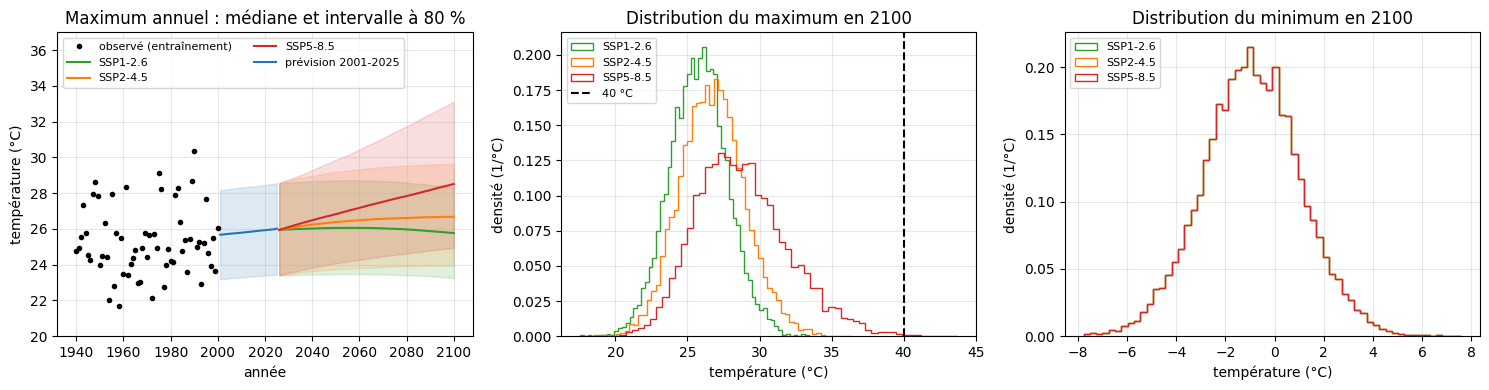

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(annee, an['max'], 'k.', label='observé (entraînement)')
for j, (s, c) in enumerate(zip(kit.SCENARIOS, ('tab:green', 'tab:orange', 'tab:red'))):
    q = np.quantile(tirer(p, co2_fut[:, j]), [.1, .5, .9], axis=1)
    ax[0].fill_between(annees_fut, q[0], q[2], color=c, alpha=.15); ax[0].plot(annees_fut, q[1], c, label=s.upper())
    for k, v in enumerate(('max', 'min')):
        ax[k + 1].hist(tir[v][1][j], bins=60, density=True, histtype='step', color=c, label=s.upper())
q = np.quantile(tir['max'][0], [.1, .5, .9], axis=1)
ax[0].fill_between(kit.ANNEES_TEST, q[0], q[2], color='tab:blue', alpha=.15); ax[0].plot(kit.ANNEES_TEST, q[1], 'tab:blue', label='prévision 2001-2025')
ax[0].set(title='Maximum annuel : médiane et intervalle à 80 %', xlabel='année', ylabel='température (°C)', ylim=(20, 37))
ax[1].axvline(40, color='k', ls='--', label='40 °C')
ax[1].set(title='Distribution du maximum en 2100', xlabel='température (°C)', ylabel='densité (1/°C)')
ax[2].set(title='Distribution du minimum en 2100', xlabel='température (°C)', ylabel='densité (1/°C)')
for a in ax: a.legend(fontsize=8, ncol=2 if a is ax[0] else 1, loc='upper left'); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 5. Discussion et limites

- **Le signal du CO$_2$ est faible sur 1940–2000** (corrélation ≈ 0,04 pour le maximum) : 61 années ne suffisent pas à fixer la pente. Le modèle le dit honnêtement à travers la largeur de la loi a posteriori de $b$, et c'est cette incertitude qui élargit fortement les prévisions sous SSP5-8.5.
- **La contrainte $b \ge 0$ est la seule connaissance ajoutée** ; c'est aussi le test de cohérence n°1 du groupe. Elle relève de la physique générale (effet de serre), pas d'une information sur 2001–2025.
- **Minimum annuel** : la validation interne retient la variante sans pente, car sur 1940–2000 le minimum annuel ne montre aucune hausse (pente estimée négative). Le modèle prédit donc un minimum stable, ce qui est physiquement discutable : les quantiles bas des températures journalières, eux, augmentent sur la même période.
- **Hypothèses fortes** : bruit gaussien (le maximum annuel est en réalité un peu asymétrique, une loi GEV serait plus adaptée aux queues, donc à la question des 40 °C) ; années indépendantes ; relation linéaire en $\ln C$ prolongée jusqu'à 946 ppm.
- **Pour le notebook final**, le même code se ré-entraîne sur 1940–2025 avec les données du prof : la coupure en 2000 ne sert qu'à la compétition.